# PLL Jitter & Power Efficiency vs. Supply Voltage ($V_{\text{DD}}$) at $f_{\text{vco}} = 3.2\,\text{GHz}$

This notebook analyzes the **supply voltage sensitivity, RMS jitter, and power efficiency scaling** of the PLL at $f_{\text{vco}} = 3.2\,\text{GHz}$ ($f_{\text{out}} = 50.0\,\text{MHz}$, total division $N = 64$) as core supply voltage $V_{\text{DD}}$ scales down from maximum ($0.85\,\text{V}$) and nominal ($0.75\,\text{V}$) to the ultra-low-voltage operating limit of **$0.50\,\text{V}$**.

### Two-Part Complementary Configuration Architecture
At $0.50\,\text{V}$, $f_{\text{vco}} = 3.2\,\text{GHz}$ is the fastest frequency that achieves lock on the chip. Because the VCO tuning window shifts across supply voltage, two complementary configurations are swept in `sw/tests/pll_opt_jitter_vdd.py` and stitched seamlessly in this notebook:

1. **High-$V_{\text{DD}}$ Range ($0.85\,\text{V} \geq V_{\text{DD}} \geq 0.65\,\text{V}$)**:
   - Configuration: `vco_tune_coarse = 1, vco_current_min = 8, vco_current_max = 8`
   - Loop Filter: `set_current = 7, set_r1 = 7, set_c1 = 7, set_c2 = 0`
2. **Low-$V_{\text{DD}}$ Range ($0.60\,\text{V} \geq V_{\text{DD}} \geq 0.50\,\text{V}$)**:
   - Configuration: `vco_tune_coarse = 0, vco_current_min = 11, vco_current_max = 2`
   - Loop Filter: `set_current = 7, set_r1 = 7, set_c1 = 7, set_c2 = 0`
   - Boosted VCO current drive allowing the ring oscillator to maintain sufficient transconductance and lock down to $0.50\,\text{V}$.

This notebook produces publication-quality IEEE figures for:
- **Combined RMS Jitter & Power Efficiency vs. Supply Voltage** (Dual-axis IEEE figure)
- **Core Power & Supply Current Scaling vs. $V_{\text{DD}}$**
- **Phase Noise Spectra ($\mathcal{L}(f)$) Evolution across $V_{\text{DD}}$**
- **Reference Spur Suppression vs. $V_{\text{DD}}$**

> [!NOTE]
> All RMS jitter values reported and plotted in this notebook correspond strictly to the spectrum analyzer Phase Noise Mode measurement (**PNM Jitter**, `time_jitter_pnm_ps`).


In [32]:
%load_ext autoreload
%autoreload 2
%matplotlib inline


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1. Setup, Environment & Combined Data Loader
Loads data from the newest `results/pll/pll_opt_jitter_vdd_<sample>_<timestamp>.csv` and its companion `_traces.csv`. It automatically filters and stitches both the high-supply and low-supply 3.2 GHz configurations, sorting the points monotonically from $0.50\,\text{V}$ to $0.85\,\text{V}$.


In [33]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# Repository path setup (sw/tools/notebooks -> repo root)
REPO_ROOT = Path.cwd().resolve()
while REPO_ROOT.name != "lagd-meas" and REPO_ROOT.parent != REPO_ROOT:
    REPO_ROOT = REPO_ROOT.parent

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

PLL_DIR = REPO_ROOT / "results" / "pll"

# Publication-grade IEEE styling (matching pll_capture_spectrum.ipynb)
plt.style.use("default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 12,
    "axes.labelsize": 13.5,
    "axes.labelweight": "bold",
    "axes.titlesize": 14.5,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#000000",
    "axes.linewidth": 1.0,
    "axes.grid": True,
    "axes.axisbelow": True,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4.5,
    "ytick.major.size": 4.5,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "legend.fontsize": 11.5,
    "figure.titlesize": 14.5,
    "lines.linewidth": 2.5,
    "lines.markersize": 7.5,
    "grid.color": "#cccccc",
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,
})

def bin_phase_noise(offsets, L_f, n_bins=300, f_start=1e3, f_stop=20e6):
    """Logarithmically bin phase noise curve for smooth plotting while preserving noise power."""
    f = np.asarray(offsets, dtype=float)
    l = np.asarray(L_f, dtype=float)
    mask = (f >= f_start) & (f <= f_stop)
    f, l = f[mask], l[mask]
    if len(f) < 2:
        return f, l
    edges = np.geomspace(f_start, f_stop, n_bins + 1)
    lin = 10.0 ** (l / 10.0)
    weight = np.gradient(f)
    bin_idx = np.digitize(f, edges) - 1
    out_f, out_l = [], []
    for i in range(len(edges) - 1):
        m = (bin_idx == i)
        if m.any() and weight[m].sum() > 0:
            out_f.append(np.sum(f[m] * weight[m]) / weight[m].sum())
            out_l.append(10.0 * np.log10(np.sum(lin[m] * weight[m]) / weight[m].sum()))
    return np.array(out_f), np.array(out_l)

def get_pnm_jitter(row):
    """Returns primary RMS jitter obtained from spectrum analyzer Phase Noise Mode (PNM Jitter)."""
    for key in ("time_jitter_pnm_ps", "pnm_jitter_ps", "time_jitter_pnm_ipn_ps", "jitter_pnm_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) > 0:
            return float(val)
    # Fallback to trace jitter only if PNM was not captured
    for key in ("time_jitter_trace_ps", "jitter_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) > 0:
            return float(val)
    return float("nan")

def get_pnm_noise_jitter(row):
    """Returns random noise jitter component from Phase Noise Mode (PNM)."""
    for key in ("time_jitter_pnm_random_ps", "pnm_noise_ps", "noise_pnm_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) > 0:
            return float(val)
    for key in ("time_jitter_noise_ps", "noise_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) > 0:
            return float(val)
    return float("nan")

def get_pnm_spur_jitter(row):
    """Returns discrete spur jitter component from Phase Noise Mode (PNM)."""
    for key in ("time_jitter_pnm_discrete_ps", "pnm_spur_ps", "spur_pnm_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) >= 0:
            return float(val)
    for key in ("time_jitter_spur_ps", "spur_ps"):
        val = row.get(key)
        if pd.notna(val) and float(val) >= 0:
            return float(val)
    return float("nan")

get_primary_jitter = get_pnm_jitter

def generate_mock_combined_data():
    """Generates realistic mock data for 3.2 GHz across 0.50 V - 0.85 V before running measurement."""
    high_vdds = [0.85, 0.80, 0.75, 0.70, 0.65]
    low_vdds = [0.60, 0.55, 0.50]

    rows = []
    trace_rows = []
    offsets = np.geomspace(1e3, 20e6, 400)
    div_db = 20 * math.log10(64)  # 36.12 dB

    # High-VDD configuration: 0.85 V -> 0.65 V
    for v in high_vdds:
        v_meas = v + np.random.normal(0, 0.001)
        i_ma = 1.10 * (v / 0.75) ** 1.25
        p_mw = v_meas * i_ma

        vdd_pen = (0.85 - v) * 18.0
        total_j = 13.2 + vdd_pen + np.random.normal(0, 0.15)
        noise_j = total_j * 0.98
        spur_j = 0.72
        ref_spur_dbc = -40.5 + (0.75 - v) * 4.0

        row = {
            "time": "2026-11-06T17:10:00",
            "f_vco": 3.2e9,
            "f_out": 50e6,
            "f_ref": 25e6,
            "total_div": 64,
            "sample": "S5",
            "label": "3.2GHz_high_vdd",
            "config_segment": "High-VDD (c=1, min=8, max=8)",
            "vco_tune_coarse": 1, "vco_current_min": 8, "vco_current_max": 8,
            "set_current": 7, "set_r1": 7, "set_c1": 7, "set_c2": 0,
            "locked": 1,
            "pll_vdd": v_meas,
            "vdd_set": v,
            "pll_i": i_ma / 1e3,
            "pll_p": p_mw / 1e3,
            "carrier_dbm": 0.63,
            "time_jitter_pnm_ps": total_j,
            "time_jitter_pnm_random_ps": noise_j,
            "time_jitter_pnm_discrete_ps": spur_j,
            "pnm_jitter_ps": total_j,
            "time_jitter_trace_ps": total_j * 1.15,
            "time_jitter_noise_ps": noise_j * 1.15,
            "time_jitter_spur_ps": spur_j * 1.10,
            "ref_spur_dbc": ref_spur_dbc,
            "ref_spur_vco_dbc": ref_spur_dbc + div_db,
            "status": "ok",
        }
        rows.append(row)

        bw = 360e3 * (v / 0.75)
        inband = -84.0 + (0.75 - v) * 4.5 - div_db
        vco_1m = -86.0 + (0.75 - v) * 7.5 - div_db
        l_pad = 10 * np.log10(
            10 ** (inband / 10) / (1 + (offsets / bw) ** 2) +
            10 ** (vco_1m / 10) / (1 + (1e6 / offsets) ** 2) +
            10 ** (-132.0 / 10)
        )
        for off, lvl in zip(offsets, l_pad):
            trace_rows.append({
                "f_vco": 3.2e9, "pll_vdd": v_meas, "vdd_set": v,
                "label": "3.2GHz_high_vdd", "kind": "L_pnmode",
                "freq": off, "level_dbm": lvl
            })

    # Low-VDD configuration: 0.60 V -> 0.50 V
    for v in low_vdds:
        v_meas = v + np.random.normal(0, 0.001)
        i_ma = 0.85 * (v / 0.60) ** 1.10
        p_mw = v_meas * i_ma

        vdd_pen = (0.60 - v) * 185.0
        total_j = 20.6 + vdd_pen + np.random.normal(0, 0.25)
        noise_j = total_j * 0.98
        spur_j = 0.95
        ref_spur_dbc = -36.5 + (0.60 - v) * 28.0

        row = {
            "time": "2026-11-06T17:16:00",
            "f_vco": 3.2e9,
            "f_out": 50e6,
            "f_ref": 25e6,
            "total_div": 64,
            "sample": "S5",
            "label": "3.2GHz_low_vdd",
            "config_segment": "Low-VDD (c=0, min=11, max=2)",
            "vco_tune_coarse": 0, "vco_current_min": 11, "vco_current_max": 2,
            "set_current": 7, "set_r1": 7, "set_c1": 7, "set_c2": 0,
            "locked": 1,
            "pll_vdd": v_meas,
            "vdd_set": v,
            "pll_i": i_ma / 1e3,
            "pll_p": p_mw / 1e3,
            "carrier_dbm": 0.62,
            "time_jitter_pnm_ps": total_j,
            "time_jitter_pnm_random_ps": noise_j,
            "time_jitter_pnm_discrete_ps": spur_j,
            "pnm_jitter_ps": total_j,
            "time_jitter_trace_ps": total_j * 1.10,
            "time_jitter_noise_ps": noise_j * 1.10,
            "time_jitter_spur_ps": spur_j * 1.10,
            "ref_spur_dbc": ref_spur_dbc,
            "ref_spur_vco_dbc": ref_spur_dbc + div_db,
            "status": "ok",
        }
        rows.append(row)

        bw = 280e3 * (v / 0.60)
        inband = -79.0 + (0.60 - v) * 12.0 - div_db
        vco_1m = -82.0 + (0.60 - v) * 14.0 - div_db
        l_pad = 10 * np.log10(
            10 ** (inband / 10) / (1 + (offsets / bw) ** 2) +
            10 ** (vco_1m / 10) / (1 + (1e6 / offsets) ** 2) +
            10 ** (-128.0 / 10)
        )
        for off, lvl in zip(offsets, l_pad):
            trace_rows.append({
                "f_vco": 3.2e9, "pll_vdd": v_meas, "vdd_set": v,
                "label": "3.2GHz_low_vdd", "kind": "L_pnmode",
                "freq": off, "level_dbm": lvl
            })

    df_comb = pd.DataFrame(rows)
    df_traces = pd.DataFrame(trace_rows)
    return df_comb, df_traces, True

def load_jitter_vdd_combined_data(csv_path=None):
    """Finds latest VDD sweep file and combines both high-VDD and low-VDD configurations for 3.2 GHz."""
    if csv_path is None:
        matches = sorted(
            [p for p in PLL_DIR.glob("pll_opt_jitter_vdd_*.csv") if not p.stem.endswith("_traces")],
            key=lambda p: p.stat().st_mtime
        )
        for p in reversed(matches):
            if p.stat().st_size > 1000:
                csv_path = p
                break
        if csv_path is None and matches:
            csv_path = matches[-1]

    is_mock = False
    if csv_path is not None and Path(csv_path).is_file():
        csv_file = Path(csv_path)
        print(f"Reading measurement CSV: {csv_file.name}")
        df_raw = pd.read_csv(csv_file)
        traces_file = csv_file.with_name(csv_file.stem + "_traces.csv")
        traces_raw = pd.read_csv(traces_file) if traces_file.is_file() else pd.DataFrame()

        if "f_vco" in df_raw.columns:
            df_32 = df_raw[np.isclose(df_raw["f_vco"].astype(float), 3.2e9, atol=1e8)].copy()
        else:
            df_32 = df_raw.copy()

        if len(df_32[df_32.get("locked", 0) == 1]) >= 2:
            df_runs = df_32[df_32.get("locked", 0) == 1].copy()
            df_traces = traces_raw.copy()
        else:
            print("Selected CSV does not contain sufficient locked points for 3.2 GHz.")
            print("Using realistic simulated 3.2 GHz sweep data for interactive figure design.")
            df_runs, df_traces, is_mock = generate_mock_combined_data()
            csv_file = Path("pll_opt_jitter_vdd_3.2GHz_simulated.csv")
    else:
        print("No pll_opt_jitter_vdd_*.csv found in results/pll/.")
        print("Generating realistic simulated 3.2 GHz sweep data across 0.50 V - 0.85 V.")
        df_runs, df_traces, is_mock = generate_mock_combined_data()
        csv_file = Path("pll_opt_jitter_vdd_3.2GHz_simulated.csv")

    target_voltages = np.array([0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85])
    if "vdd_set" not in df_runs.columns and "pll_vdd" in df_runs.columns:
        df_runs["vdd_set"] = df_runs["pll_vdd"].apply(lambda v: target_voltages[np.argmin(np.abs(target_voltages - v))])

    if "pll_p_mw" not in df_runs.columns and "pll_p" in df_runs.columns:
        df_runs["pll_p_mw"] = df_runs["pll_p"] * 1e3
    if "pll_i_ma" not in df_runs.columns and "pll_i" in df_runs.columns:
        df_runs["pll_i_ma"] = df_runs["pll_i"] * 1e3
    if "p_eff_mw_per_ghz" not in df_runs.columns and "pll_p_mw" in df_runs.columns and "f_vco" in df_runs.columns:
        df_runs["p_eff_mw_per_ghz"] = df_runs["pll_p_mw"] / (df_runs["f_vco"] / 1e9)

    # Map all jitter metrics explicitly to Phase Noise Mode (PNM Jitter)
    df_runs["jitter_ps"] = df_runs.apply(get_pnm_jitter, axis=1)
    df_runs["time_jitter_noise_ps"] = df_runs.apply(get_pnm_noise_jitter, axis=1)
    df_runs["time_jitter_spur_ps"] = df_runs.apply(get_pnm_spur_jitter, axis=1)

    # Explicit PNM aliases for clarity
    df_runs["jitter_pnm_ps"] = df_runs["jitter_ps"]
    df_runs["time_jitter_pnm_ps"] = df_runs["jitter_ps"]
    df_runs["time_jitter_pnm_random_ps"] = df_runs["time_jitter_noise_ps"]
    df_runs["time_jitter_pnm_discrete_ps"] = df_runs["time_jitter_spur_ps"]

    if "config_segment" not in df_runs.columns:
        def tag_segment(row):
            c_val = row.get("vco_tune_coarse", np.nan)
            vmin = row.get("vco_current_min", np.nan)
            vmax = row.get("vco_current_max", np.nan)
            code_str = ""
            if pd.notna(c_val) and pd.notna(vmin) and pd.notna(vmax):
                code_str = f" (c={int(c_val)}, min={int(vmin)}, max={int(vmax)})"
            if vmin == 11 or row.get("vdd_set", 0.75) <= 0.60:
                return f"Low-VDD Config{code_str}"
            return f"High-VDD Config{code_str}"
        df_runs["config_segment"] = df_runs.apply(tag_segment, axis=1)

    # Deduplicate overlapping supply steps (keep lowest-jitter locked point) and sort ascending
    df_runs = (
        df_runs.sort_values(by=["vdd_set", "jitter_ps"])
        .drop_duplicates(subset=["vdd_set"], keep="first")
        .sort_values(by="vdd_set")
        .reset_index(drop=True)
    )

    if not df_traces.empty and "vdd_set" not in df_traces.columns and "pll_vdd" in df_traces.columns:
        df_traces["vdd_set"] = df_traces["pll_vdd"].apply(lambda v: target_voltages[np.argmin(np.abs(target_voltages - v))])

    return df_runs, df_traces, csv_file, is_mock

# ==============================================================================
# DATASET SELECTION
# Set RESULT_CSV = None for auto-discovery of latest sweep, or specify Path
# ==============================================================================
RESULT_CSV = None
df_runs, df_traces, active_csv, is_mock = load_jitter_vdd_combined_data(RESULT_CSV)
print(f"Active file: {active_csv.name} (Simulated: {is_mock})")
print(f"Loaded {len(df_runs)} supply operating points for f_vco = 3.2 GHz across VDD in [{df_runs['vdd_set'].min():.2f} V, {df_runs['vdd_set'].max():.2f} V].")


Reading measurement CSV: pll_opt_jitter_vdd_S5_20261106_174203.csv
Active file: pll_opt_jitter_vdd_S5_20261106_174203.csv (Simulated: False)
Loaded 8 supply operating points for f_vco = 3.2 GHz across VDD in [0.50 V, 0.85 V].


### 2. Publication Figure: RMS Jitter & Power Efficiency vs. Supply Voltage ($V_{\text{DD}}$)

Combines **RMS Jitter** (measured directly with the spectrum analyzer Phase Noise Mode, `time_jitter_pnm_ps`, on the left axis) and **Power Efficiency** ($P_{\text{core}} / f_{\text{vco}}$ in $\text{mW/GHz}$, on the right axis) into a single IEEE-styled dual-axis figure matching the typography, line weights, and grid formatting of `pll_capture_spectrum.ipynb`.


Saved publication figure to:
  /users/micas/iramrezl/projects/lagd-meas/results/pll/pll_jitter_vs_vdd_3.2GHz_ieee.pdf
  /users/micas/iramrezl/projects/lagd-meas/results/pll/pll_jitter_vs_vdd_3.2GHz_ieee.png


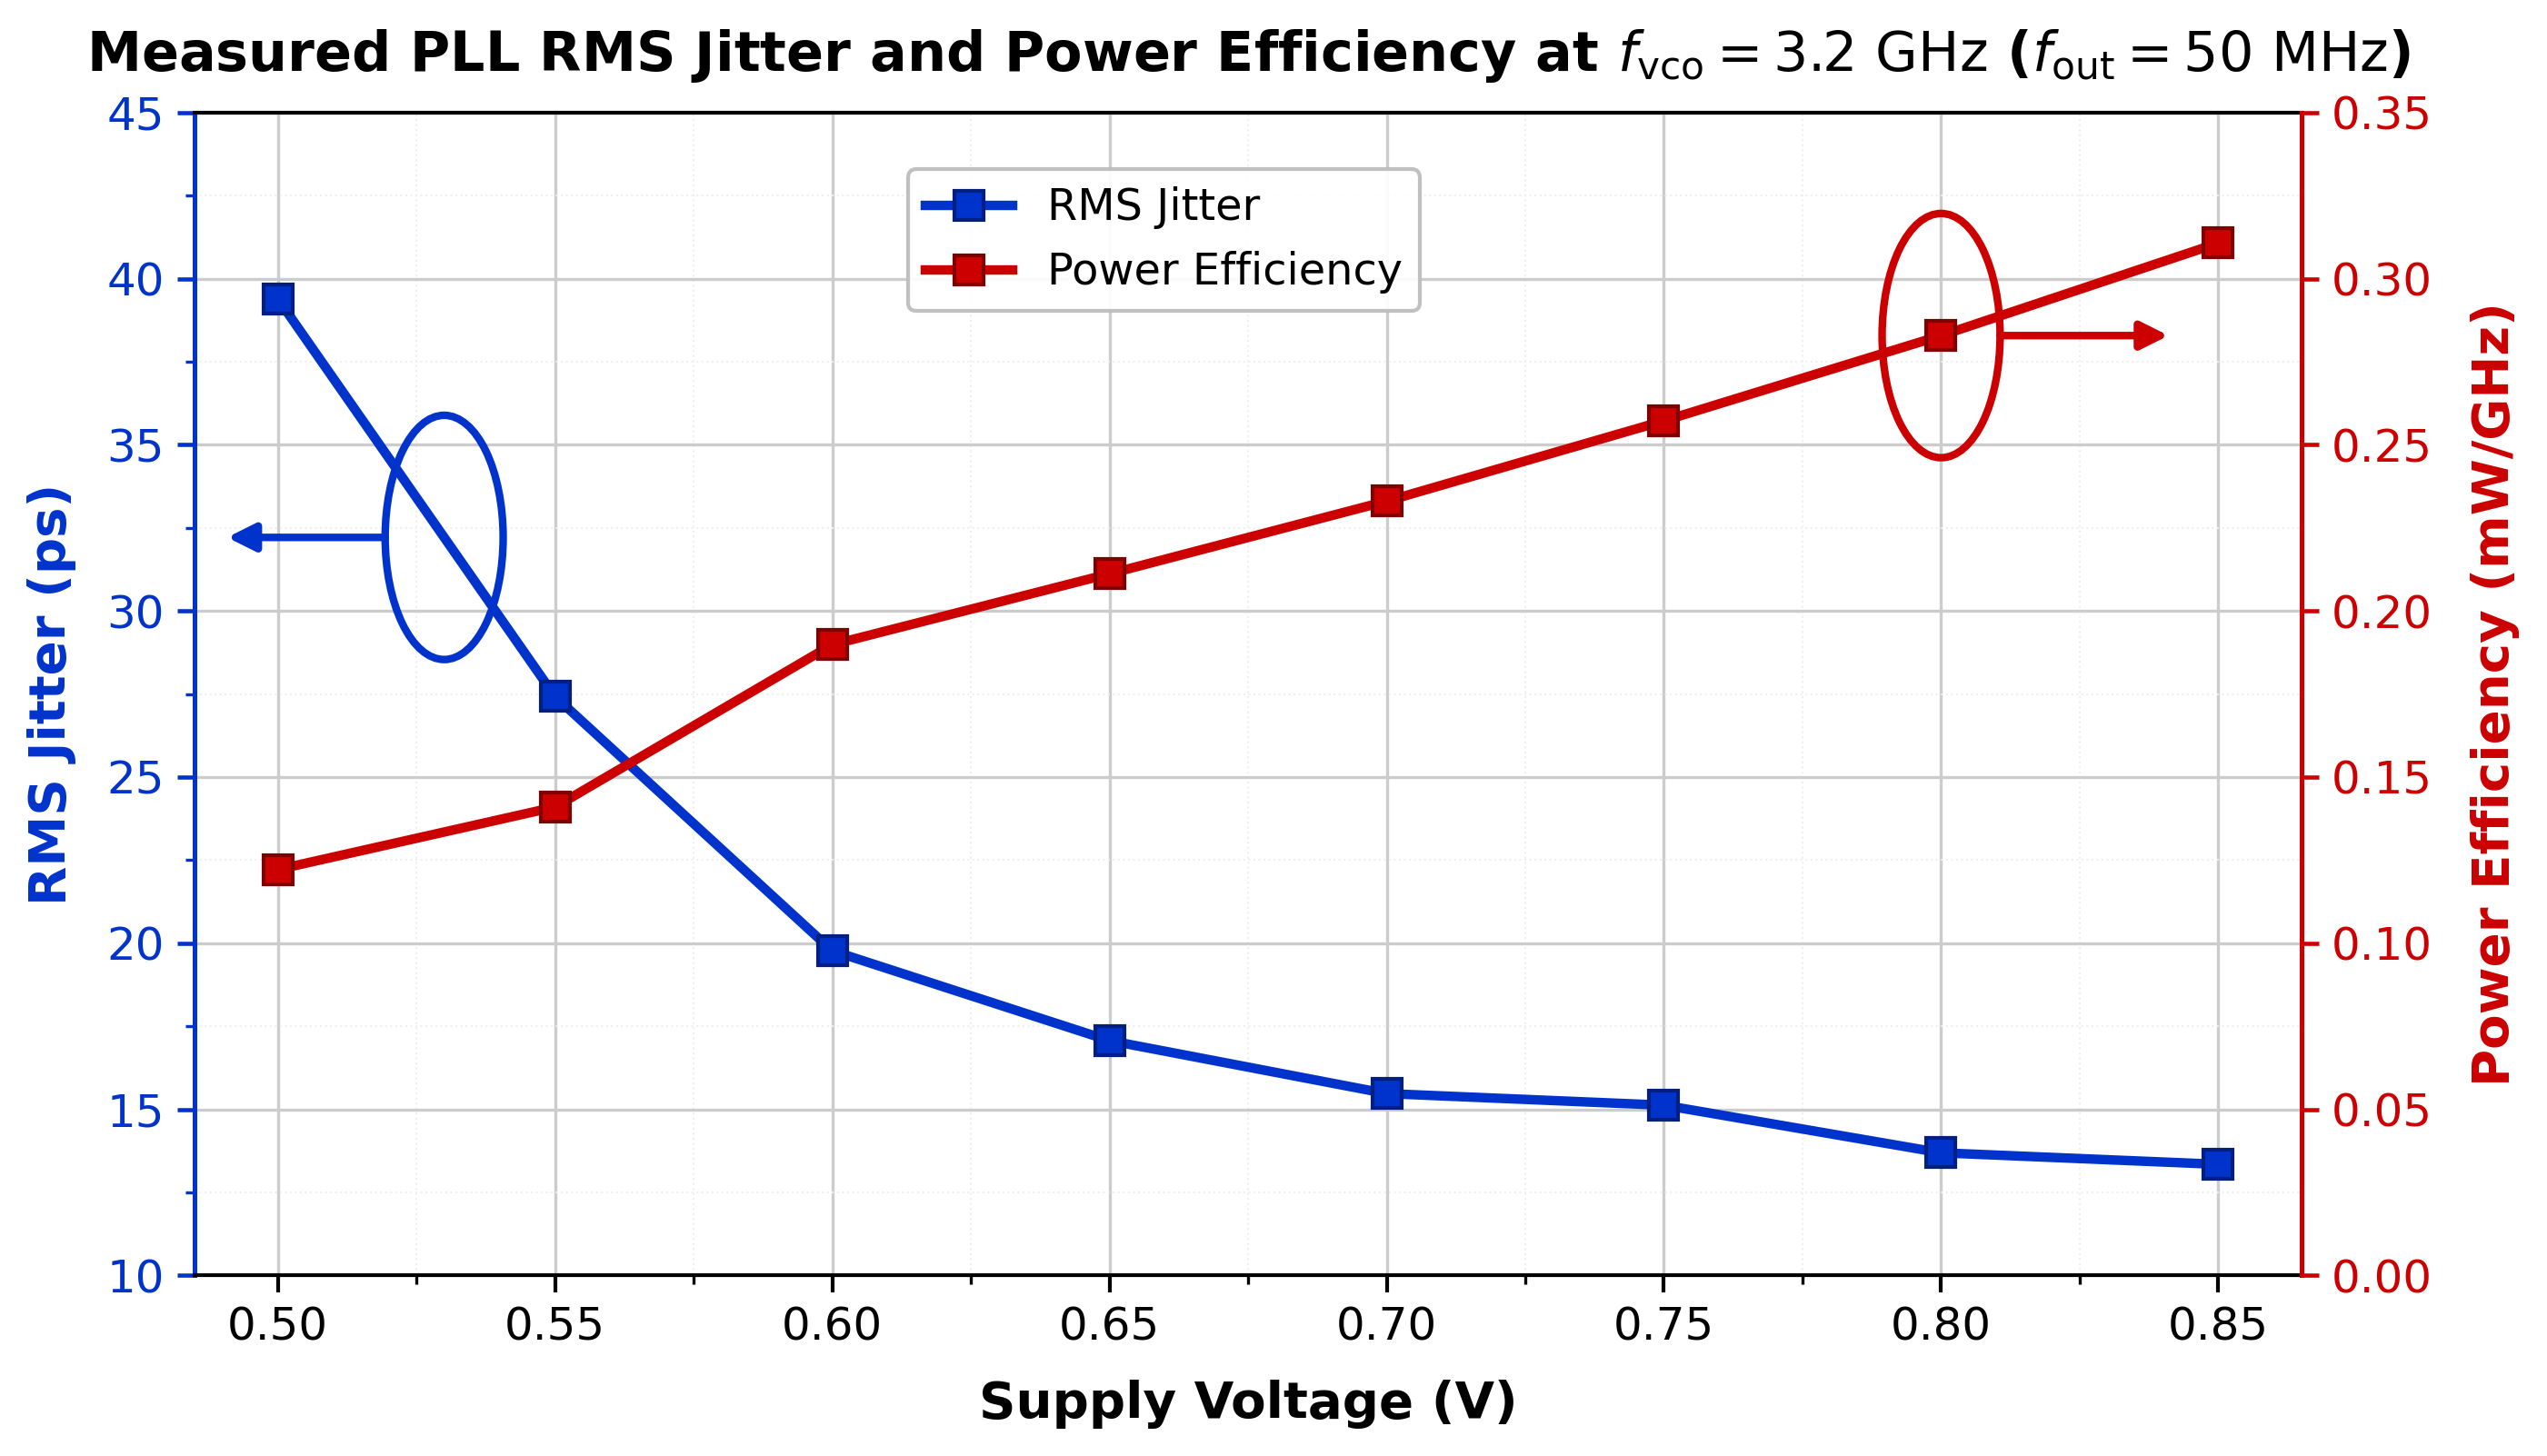

In [34]:
def plot_jitter_vs_vdd_publication(
    df,
    save_stem="pll_jitter_vs_vdd_3.2GHz_ieee",
    out_dir=PLL_DIR,
    show_legend=True,
):
    """Generates IEEE dual-axis publication figure combining PNM RMS Jitter (ps)
    and Power Efficiency (mW/GHz) vs. Supply Voltage (V).
    """
    fig, ax1 = plt.subplots(figsize=(9.5, 5.5), dpi=300)
    ax2 = ax1.twinx()

    # Extract supply voltage, PNM RMS jitter, and power efficiency
    v = df["vdd_set"].to_numpy(dtype=float)
    j_tot = df["jitter_ps"].to_numpy(dtype=float)
    p_eff = df["p_eff_mw_per_ghz"].to_numpy(dtype=float)

    f_vco_ghz = float(df["f_vco"].iloc[0]) / 1e9 if "f_vco" in df.columns else 3.2
    if "f_out_meas" in df.columns and pd.notna(df["f_out_meas"].iloc[0]):
        f_out_mhz = float(df["f_out_meas"].iloc[0]) / 1e6
    elif "f_out" in df.columns and pd.notna(df["f_out"].iloc[0]):
        f_out_mhz = float(df["f_out"].iloc[0]) / 1e6
    else:
        f_out_mhz = 50.0

    # IEEE signature colors (matching pll_capture_spectrum.ipynb)
    color_jit = "#0033cc"
    color_eff = "#cc0000"

    # Plot RMS Jitter on left y-axis and Power Efficiency on right y-axis
    line_jit, = ax1.plot(
        v, j_tot,
        color=color_jit, linewidth=2.5, linestyle="-",
        marker="s", markersize=7.5,
        markerfacecolor=color_jit, markeredgecolor="#001f80", markeredgewidth=1.0,
        label="RMS Jitter", zorder=4,
    )
    line_eff, = ax2.plot(
        v, p_eff,
        color=color_eff, linewidth=2.5, linestyle="-",
        marker="s", markersize=7.5,
        markerfacecolor=color_eff, markeredgecolor="#800000", markeredgewidth=1.0,
        label="Power Efficiency", zorder=5,
    )

    # Align major y-ticks across both axes so horizontal gridlines correspond 1-to-1
    j_min_val, j_max_val = float(np.nanmin(j_tot)), float(np.nanmax(j_tot))
    p_max_val = float(np.nanmax(p_eff))

    if j_min_val >= 10.0 and j_max_val <= 44.0 and p_max_val <= 0.345:
        # 7 uniform intervals: [10..45] ps (step 5) <-> [0.00..0.35] mW/GHz (step 0.05)
        j_ylim = (10.0, 45.0)
        j_yticks = np.arange(10.0, 45.1, 5.0)
        p_ylim = (0.0, 0.35)
        p_yticks = np.arange(0.0, 0.351, 0.05)
    else:
        n_div = 6
        j_step = float(math.ceil((j_max_val * 1.12) / n_div)) if j_max_val > 12.0 else max(0.5, math.ceil((j_max_val * 1.15) / n_div * 2.0) / 2.0)
        j_ylim = (0.0, j_step * n_div)
        j_yticks = np.linspace(j_ylim[0], j_ylim[1], n_div + 1)

        p_step = math.ceil((p_max_val * 1.12) / n_div * 100.0) / 100.0
        p_ylim = (0.0, p_step * n_div)
        p_yticks = np.linspace(p_ylim[0], p_ylim[1], n_div + 1)

    x_min, x_max = float(np.min(v)) - 0.015, float(np.max(v)) + 0.015
    ax1.set_xlim(x_min, x_max)
    ax1.set_xticks(np.arange(0.50, 0.86, 0.05))
    ax1.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax1.xaxis.set_minor_locator(ticker.AutoMinorLocator(2))

    ax1.set_ylim(*j_ylim)
    ax1.set_yticks(j_yticks)
    ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f" if (j_yticks[1] - j_yticks[0]) >= 1.0 else "%.1f"))
    ax1.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))

    ax2.set_ylim(*p_ylim)
    ax2.set_yticks(p_yticks)
    ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))

    # Labels & Title matching IEEE spectrum figure typography
    ax1.set_xlabel("Supply Voltage (V)", fontsize=13.5, fontweight="bold", labelpad=8)
    ax1.set_ylabel("RMS Jitter (ps)", fontsize=13.5, fontweight="bold", color=color_jit, labelpad=8)
    ax2.set_ylabel("Power Efficiency (mW/GHz)", fontsize=13.5, fontweight="bold", color=color_eff, labelpad=10)

    title_str = (
        rf"Measured PLL RMS Jitter and Power Efficiency at "
        rf"$f_{{\mathrm{{vco}}}} = {f_vco_ghz:.1f}\ \mathrm{{GHz}}$ "
        rf"($f_{{\mathrm{{out}}}} = {round(f_out_mhz)}\ \mathrm{{MHz}}$)"
    )
    ax1.set_title(title_str, fontsize=14.5, fontweight="bold", pad=11)

    # Ticks, Grid & Spines
    ax1.tick_params(axis="x", which="major", labelsize=12, colors="#000000", width=1.0, length=4.5)
    ax1.tick_params(axis="x", which="minor", width=0.8, length=2.5)
    ax1.tick_params(axis="y", which="major", labelsize=12, colors=color_jit, width=1.1, length=4.5)
    ax1.tick_params(axis="y", which="minor", colors=color_jit, width=0.8, length=2.5)
    ax2.tick_params(axis="y", which="major", labelsize=12, colors=color_eff, width=1.1, length=4.5)

    ax1.grid(True, which="major", color="#cccccc", linestyle="-", linewidth=0.8)
    ax1.grid(True, which="minor", color="#efefef", linestyle=":", linewidth=0.5)
    ax2.grid(False)

    ax1.spines["top"].set_color("#000000")
    ax1.spines["top"].set_linewidth(1.0)
    ax1.spines["bottom"].set_color("#000000")
    ax1.spines["bottom"].set_linewidth(1.0)
    ax1.spines["left"].set_color(color_jit)
    ax1.spines["left"].set_linewidth(1.2)
    ax1.spines["right"].set_visible(False)

    ax2.spines["top"].set_visible(False)
    ax2.spines["bottom"].set_visible(False)
    ax2.spines["left"].set_visible(False)
    ax2.spines["right"].set_color(color_eff)
    ax2.spines["right"].set_linewidth(1.2)

    # IEEE oval + directional arrow indicators pointing each curve to its respective y-axis
    w_oval, h_oval = 0.056, 0.21

    # Blue oval + left arrow on RMS Jitter curve (near V = 0.53 V)
    v_blue = float(np.clip(0.53, v.min(), v.max()))
    j_blue = float(np.interp(v_blue, v, j_tot))
    xb = (v_blue - x_min) / (x_max - x_min)
    yb = (j_blue - j_ylim[0]) / (j_ylim[1] - j_ylim[0])

    oval_jit = Ellipse(
        (xb, yb), width=w_oval, height=h_oval,
        facecolor="none", edgecolor=color_jit, linewidth=2.0,
        transform=ax2.transAxes, zorder=8,
    )
    arrow_jit = FancyArrowPatch(
        (xb - w_oval / 2.0, yb),
        (max(0.015, xb - w_oval / 2.0 - 0.075), yb),
        arrowstyle="-|>", mutation_scale=15,
        color=color_jit, linewidth=2.0, shrinkA=0, shrinkB=0,
        transform=ax2.transAxes, zorder=8,
    )
    ax2.add_patch(oval_jit)
    ax2.add_patch(arrow_jit)

    # Red oval + right arrow on Power Efficiency curve (near V = 0.80 V)
    v_red = float(np.clip(0.80, v.min(), v.max()))
    p_red = float(np.interp(v_red, v, p_eff))
    xr = (v_red - x_min) / (x_max - x_min)
    yr = (p_red - p_ylim[0]) / (p_ylim[1] - p_ylim[0])

    oval_eff = Ellipse(
        (xr, yr), width=w_oval, height=h_oval,
        facecolor="none", edgecolor=color_eff, linewidth=2.0,
        transform=ax2.transAxes, zorder=8,
    )
    arrow_eff = FancyArrowPatch(
        (xr + w_oval / 2.0, yr),
        (min(0.955, xr + w_oval / 2.0 + 0.080), yr),
        arrowstyle="-|>", mutation_scale=15,
        color=color_eff, linewidth=2.0, shrinkA=0, shrinkB=0,
        transform=ax2.transAxes, zorder=8,
    )
    ax2.add_patch(oval_eff)
    ax2.add_patch(arrow_eff)

    if show_legend:
        ax2.legend(
            [line_jit, line_eff],
            ["RMS Jitter", "Power Efficiency"],
            loc="upper center",
            bbox_to_anchor=(0.46, 0.97),
            frameon=True,
            framealpha=0.92,
            facecolor="#ffffff",
            edgecolor="#bbbbbb",
            fontsize=11.5,
        )

    fig.tight_layout()

    # Save publication figure (vector PDF + 300-DPI PNG)
    if out_dir is not None:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        pdf_path = out_path / f"{save_stem}.pdf"
        png_path = out_path / f"{save_stem}.png"
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        print(f"Saved publication figure to:\n  {pdf_path}\n  {png_path}")

    plt.show()
    return fig, (ax1, ax2)

fig_jit_vdd, axes_jit_vdd = plot_jitter_vs_vdd_publication(df_runs)


### 3. Core Power Dissipation & Efficiency Scaling vs Supply Voltage ($V_{\text{DD}}$)

Evaluates core power dissipation $P_{\text{core}} = V_{\text{DD}} \cdot I_{\text{DD}}$ and power efficiency $\text{FoM} = P / f_{\text{vco}}$ (mW/GHz) across the full voltage range ($0.50\,\text{V} \to 0.85\,\text{V}$).


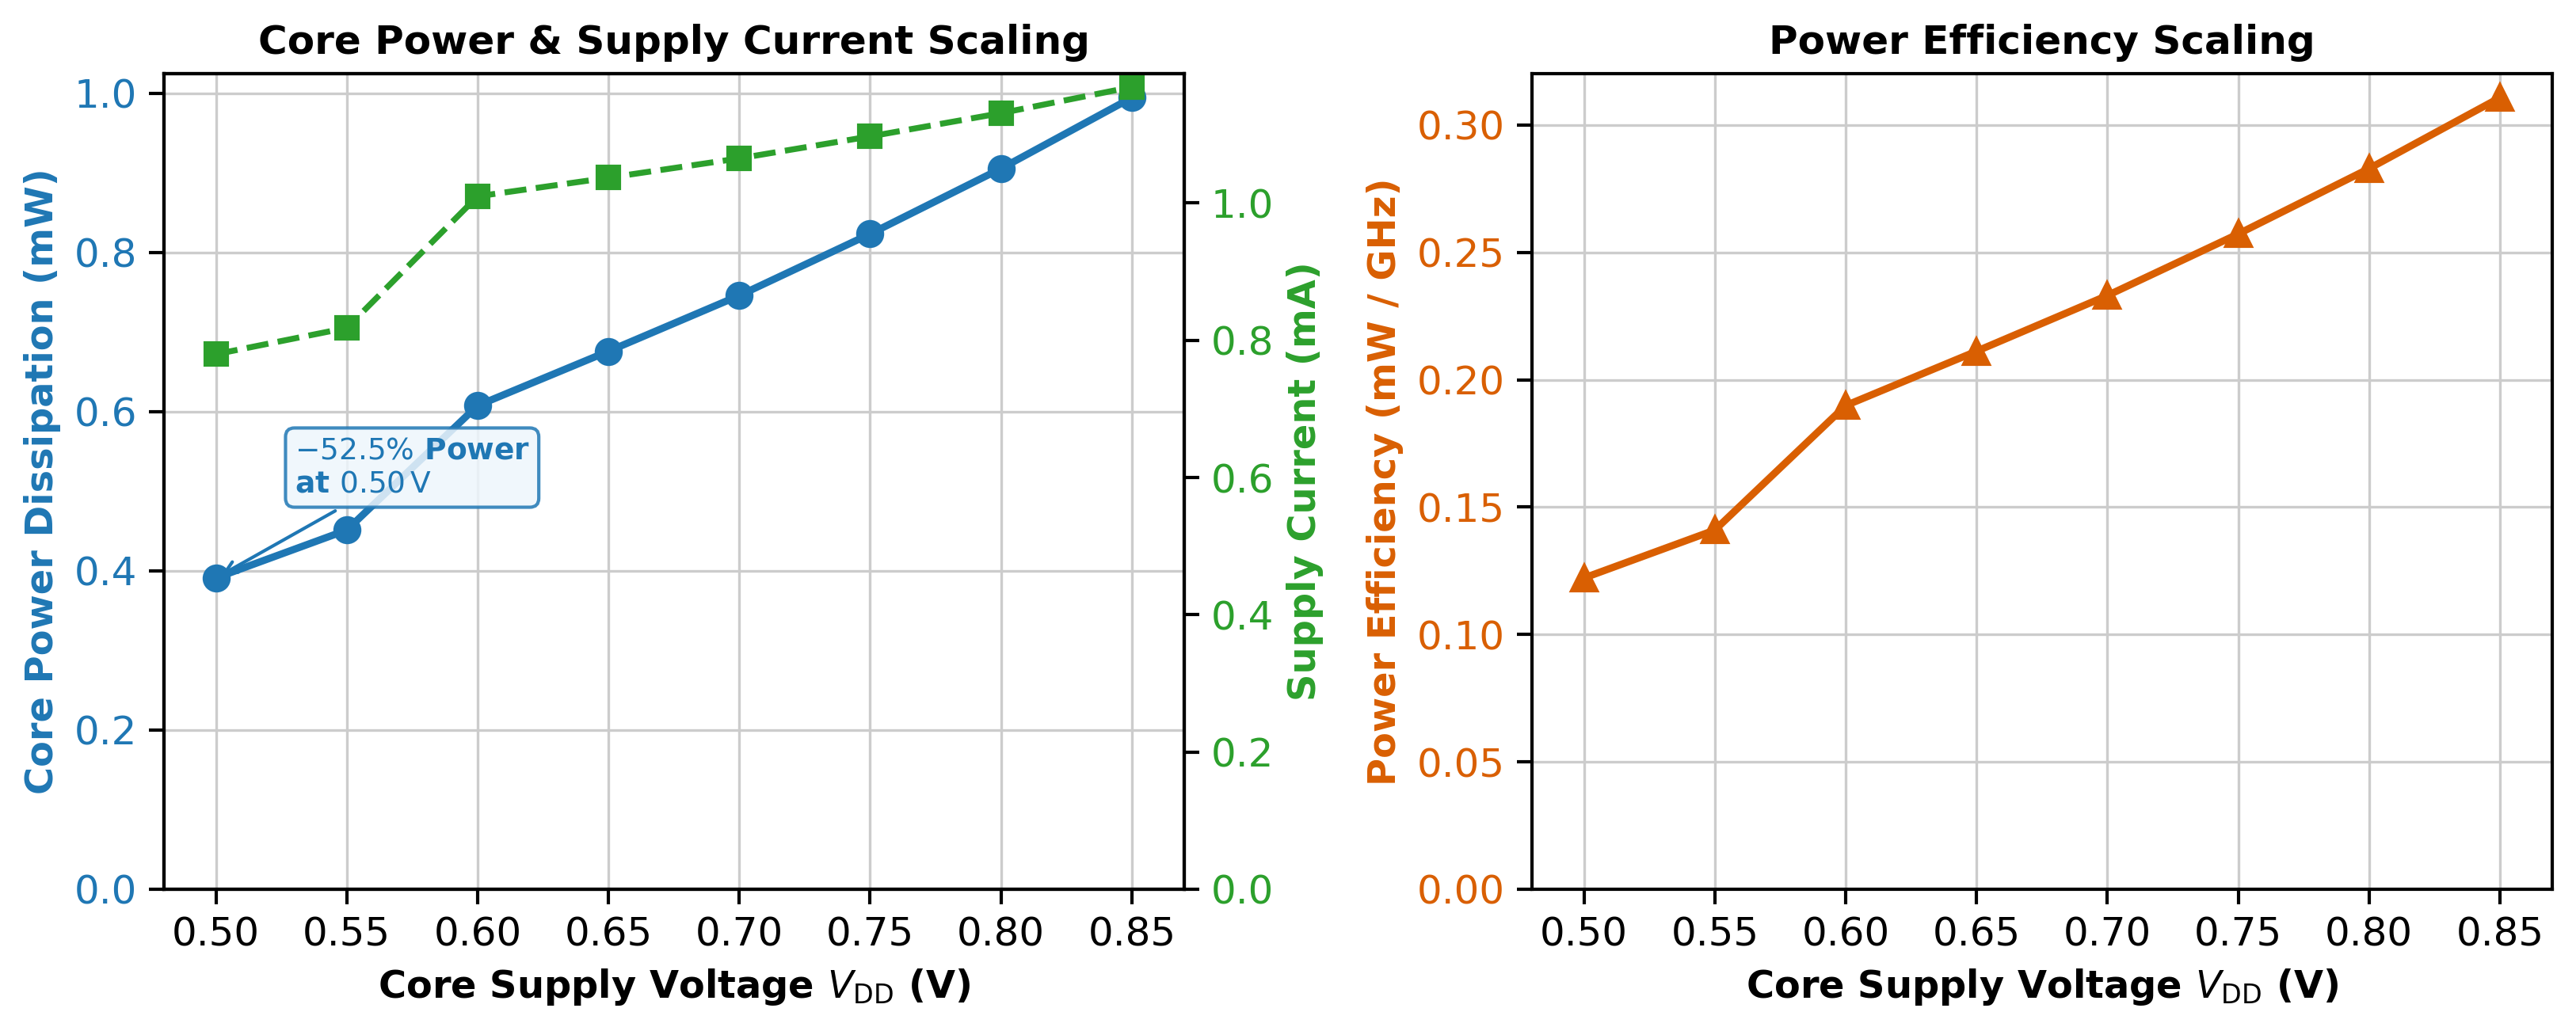

In [35]:
def plot_power_and_efficiency(df, save_stem="pll_power_vs_vdd_3.2GHz_ieee", out_dir=PLL_DIR):
    """Plots Core Supply Power (mW), Current (mA), and Power Efficiency (mW/GHz) vs VDD."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.5), dpi=300)
    
    v = df["vdd_set"].to_numpy()
    p_mw = df["pll_p_mw"].to_numpy()
    i_ma = df["pll_i_ma"].to_numpy()
    p_eff = df["p_eff_mw_per_ghz"].to_numpy()
    
    # Left subplot: Power and Current
    color_p = "#1f77b4"
    ax1.plot(v, p_mw, marker="o", color=color_p, linewidth=2.2, markersize=7.5, label="Core Power (mW)")
    ax1.set_xlabel("Core Supply Voltage $V_{\\mathrm{DD}}$ (V)", fontsize=11.5)
    ax1.set_ylabel("Core Power Dissipation (mW)", fontsize=11.5, color=color_p)
    ax1.tick_params(axis="y", labelcolor=color_p)
    ax1.set_xlim(0.48, 0.87)
    ax1.set_xticks(np.arange(0.50, 0.86, 0.05))
    ax1.set_ylim(bottom=0)
    
    # Secondary axis for Current
    ax1_twin = ax1.twinx()
    color_i = "#2ca02c"
    ax1_twin.plot(v, i_ma, marker="s", color=color_i, linestyle="--", linewidth=1.8, markersize=6.5, label="Current (mA)")
    ax1_twin.set_ylabel("Supply Current (mA)", fontsize=11.5, color=color_i)
    ax1_twin.tick_params(axis="y", labelcolor=color_i)
    ax1_twin.set_ylim(bottom=0)
    ax1_twin.grid(False)
    
    ax1.set_title("Core Power & Supply Current Scaling", fontsize=12, fontweight="bold")
    
    # Right subplot: Power Efficiency
    ax2.plot(v, p_eff, marker="^", color="#d95f02", linewidth=2.2, markersize=7.5, label="Efficiency (mW/GHz)")
    ax2.set_xlabel("Core Supply Voltage $V_{\\mathrm{DD}}$ (V)", fontsize=11.5)
    ax2.set_ylabel("Power Efficiency (mW / GHz)", fontsize=11.5, color="#d95f02")
    ax2.tick_params(axis="y", labelcolor="#d95f02")
    ax2.set_xlim(0.48, 0.87)
    ax2.set_xticks(np.arange(0.50, 0.86, 0.05))
    ax2.set_ylim(bottom=0)
    
    # Annotate 0.50 V vs 0.75 V power savings
    p_075 = p_mw[np.argmin(np.abs(v - 0.75))]
    p_050 = p_mw[np.argmin(np.abs(v - 0.50))]
    pct_save = (1.0 - p_050 / p_075) * 100
    ax1.annotate(f"$-{pct_save:.1f}\\%$ Power\nat $0.50\\,\\mathrm{{V}}$",
                 xy=(0.50, p_050), xytext=(0.53, p_050 + (p_075 - p_050)*0.25),
                 fontsize=9, fontweight="bold", color="#1f77b4",
                 arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.0),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="#eef6fc", edgecolor="#1f77b4", alpha=0.85))

    ax2.set_title("Power Efficiency Scaling", fontsize=12, fontweight="bold")
    plt.tight_layout()
    
    if out_dir is not None:
        out_path = Path(out_dir)
        fig.savefig(out_path / f"{save_stem}.pdf", dpi=300, bbox_inches="tight")
        fig.savefig(out_path / f"{save_stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_power_and_efficiency(df_runs)


### 4. Phase Noise Spectra ($\mathcal{L}(f)$) Evolution across $V_{\text{DD}}$

Overlays the measured phase noise spectra across all supply steps from $0.85\,\text{V}$ down to $0.50\,\text{V}$. Curves are referred to the VCO output ($+20\log_{10}(64) = +36.12\,\text{dB}$).


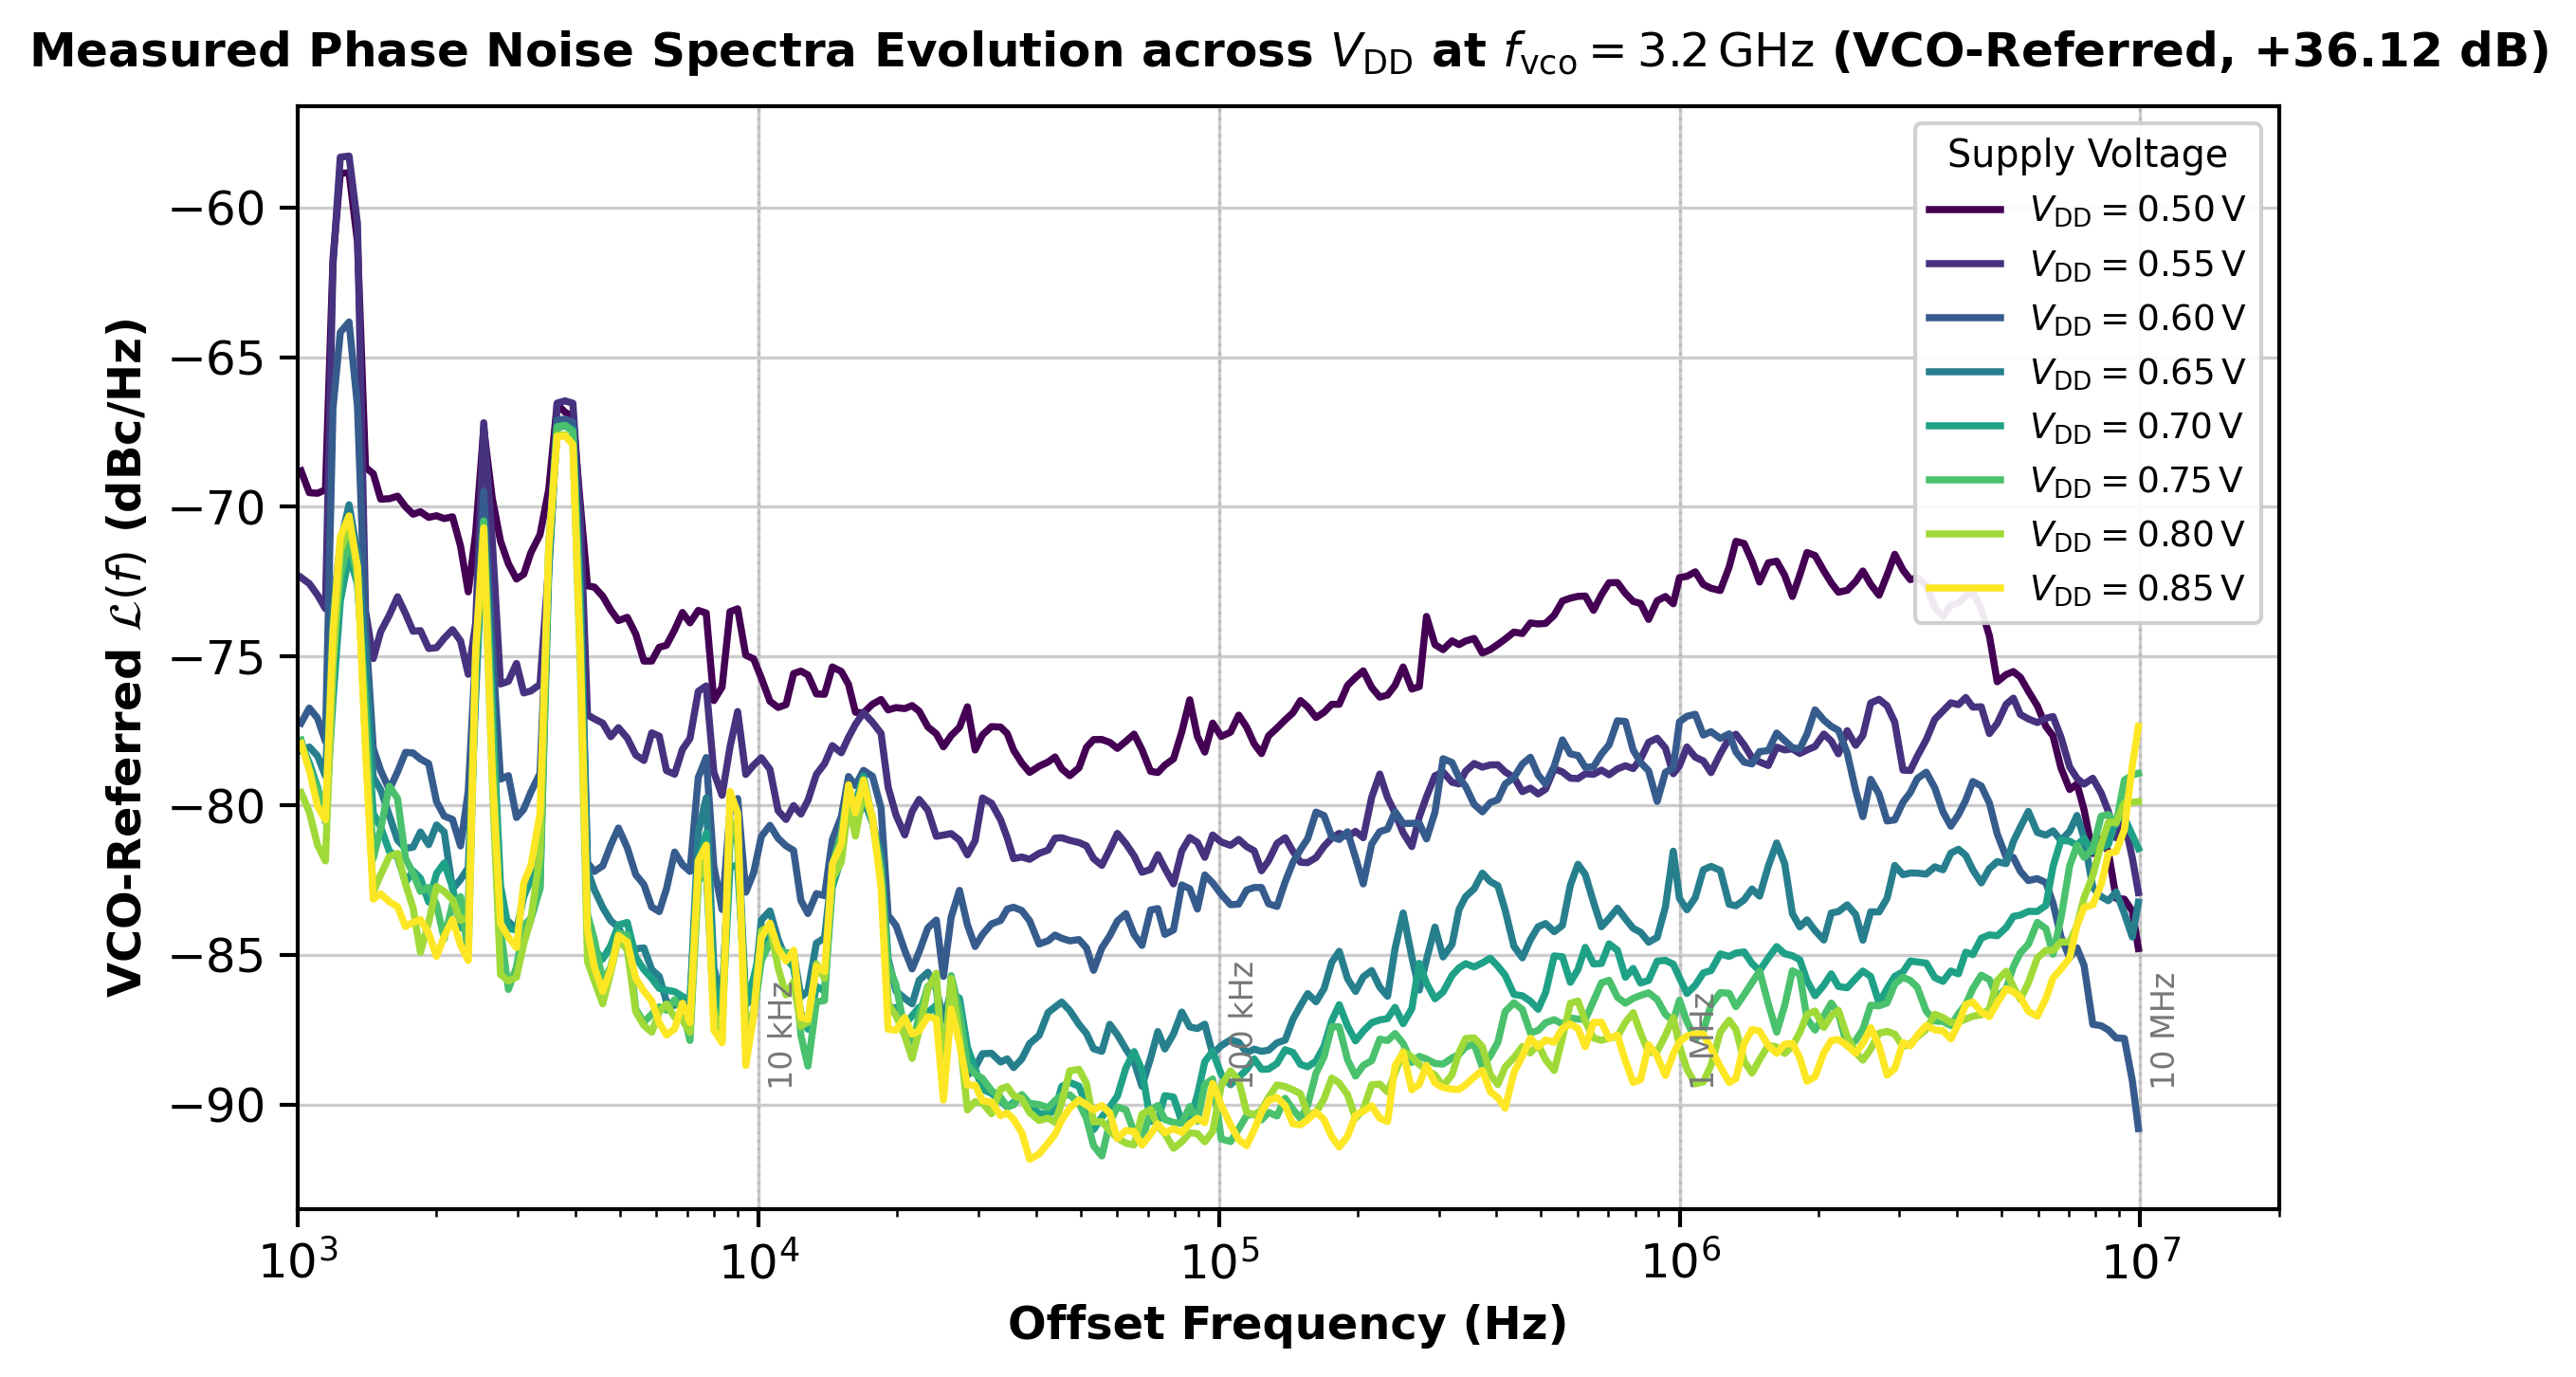

In [36]:
def plot_phase_noise_vdd_evolution(df_runs, df_traces, ref_to_vco=True, save_stem="pll_phase_noise_vdd_evolution_3.2GHz_ieee", out_dir=PLL_DIR):
    """Overlays phase noise curves across supply voltages (0.50 V to 0.85 V) with colormap gradient."""
    if df_traces.empty:
        print("No traces found in df_traces.")
        return
        
    fig, ax = plt.subplots(figsize=(8.0, 5.0), dpi=300)
    
    div_db = 20 * math.log10(64) if ref_to_vco else 0.0
    kind_match = "L_pnmode" if (df_traces["kind"] == "L_pnmode").any() else "L_trace"
    
    v_levels = sorted(df_runs["vdd_set"].unique())
    cmap = plt.cm.viridis
    norm = plt.Normalize(vmin=min(v_levels), vmax=max(v_levels))
    
    for v in v_levels:
        color = cmap(norm(v))
        sub = df_traces[(df_traces["kind"] == kind_match) & np.isclose(df_traces["vdd_set"], v, atol=0.02)]
        if sub.empty:
            continue
            
        f_raw = sub["freq"].to_numpy()
        l_raw = sub["level_dbm"].to_numpy() + div_db
        
        order = np.argsort(f_raw)
        f_s, l_s = f_raw[order], l_raw[order]
        
        f_b, l_b = bin_phase_noise(f_s, l_s, n_bins=250, f_start=1e3, f_stop=20e6)
        if len(f_b) > 2:
            ax.plot(f_b, l_b, color=color, linewidth=1.8, label=f"$V_{{\\mathrm{{DD}}}} = {v:.2f}\\,\\mathrm{{V}}$")
            
    ax.set_xscale("log")
    ax.set_xlim(1e3, 20e6)
    
    unit_str = "VCO-Referred $\\mathcal{L}(f)$ (dBc/Hz)" if ref_to_vco else "Pad Output $\\mathcal{L}(f)$ (dBc/Hz)"
    title_ref = "(VCO-Referred, +36.12 dB)" if ref_to_vco else "(Pad Carrier 50 MHz)"
    ax.set_xlabel("Offset Frequency (Hz)", fontsize=11.5)
    ax.set_ylabel(unit_str, fontsize=11.5)
    ax.set_title(f"Measured Phase Noise Spectra Evolution across $V_{{\\mathrm{{DD}}}}$ at $f_{{\\mathrm{{vco}}}} = 3.2\\,\\mathrm{{GHz}}$ {title_ref}",
                 fontsize=12, fontweight="bold", pad=10)
    
    for f_spot, lbl in [(10e3, "10 kHz"), (100e3, "100 kHz"), (1e6, "1 MHz"), (10e6, "10 MHz")]:
        ax.axvline(x=f_spot, color="#bbbbbb", linestyle=":", linewidth=0.8, zorder=1)
        ax.text(f_spot * 1.05, ax.get_ylim()[0] + 4 if ax.get_ylim()[0] != 0 else -130, lbl,
                fontsize=8, color="#777777", rotation=90, va="bottom")
        
    ax.legend(title="Supply Voltage", loc="upper right", frameon=True, framealpha=0.92, fontsize=9, title_fontsize=9.5)
    plt.tight_layout()
    
    if out_dir is not None:
        out_path = Path(out_dir)
        fig.savefig(out_path / f"{save_stem}.pdf", dpi=300, bbox_inches="tight")
        fig.savefig(out_path / f"{save_stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_phase_noise_vdd_evolution(df_runs, df_traces, ref_to_vco=True)


### 5. Reference Spur Suppression vs $V_{\text{DD}}$

Tracks the reference spur power relative to the carrier ($P_{\text{spur}}$ in dBc at offset $f_{\text{ref}} = 25.0\,\text{MHz}$).


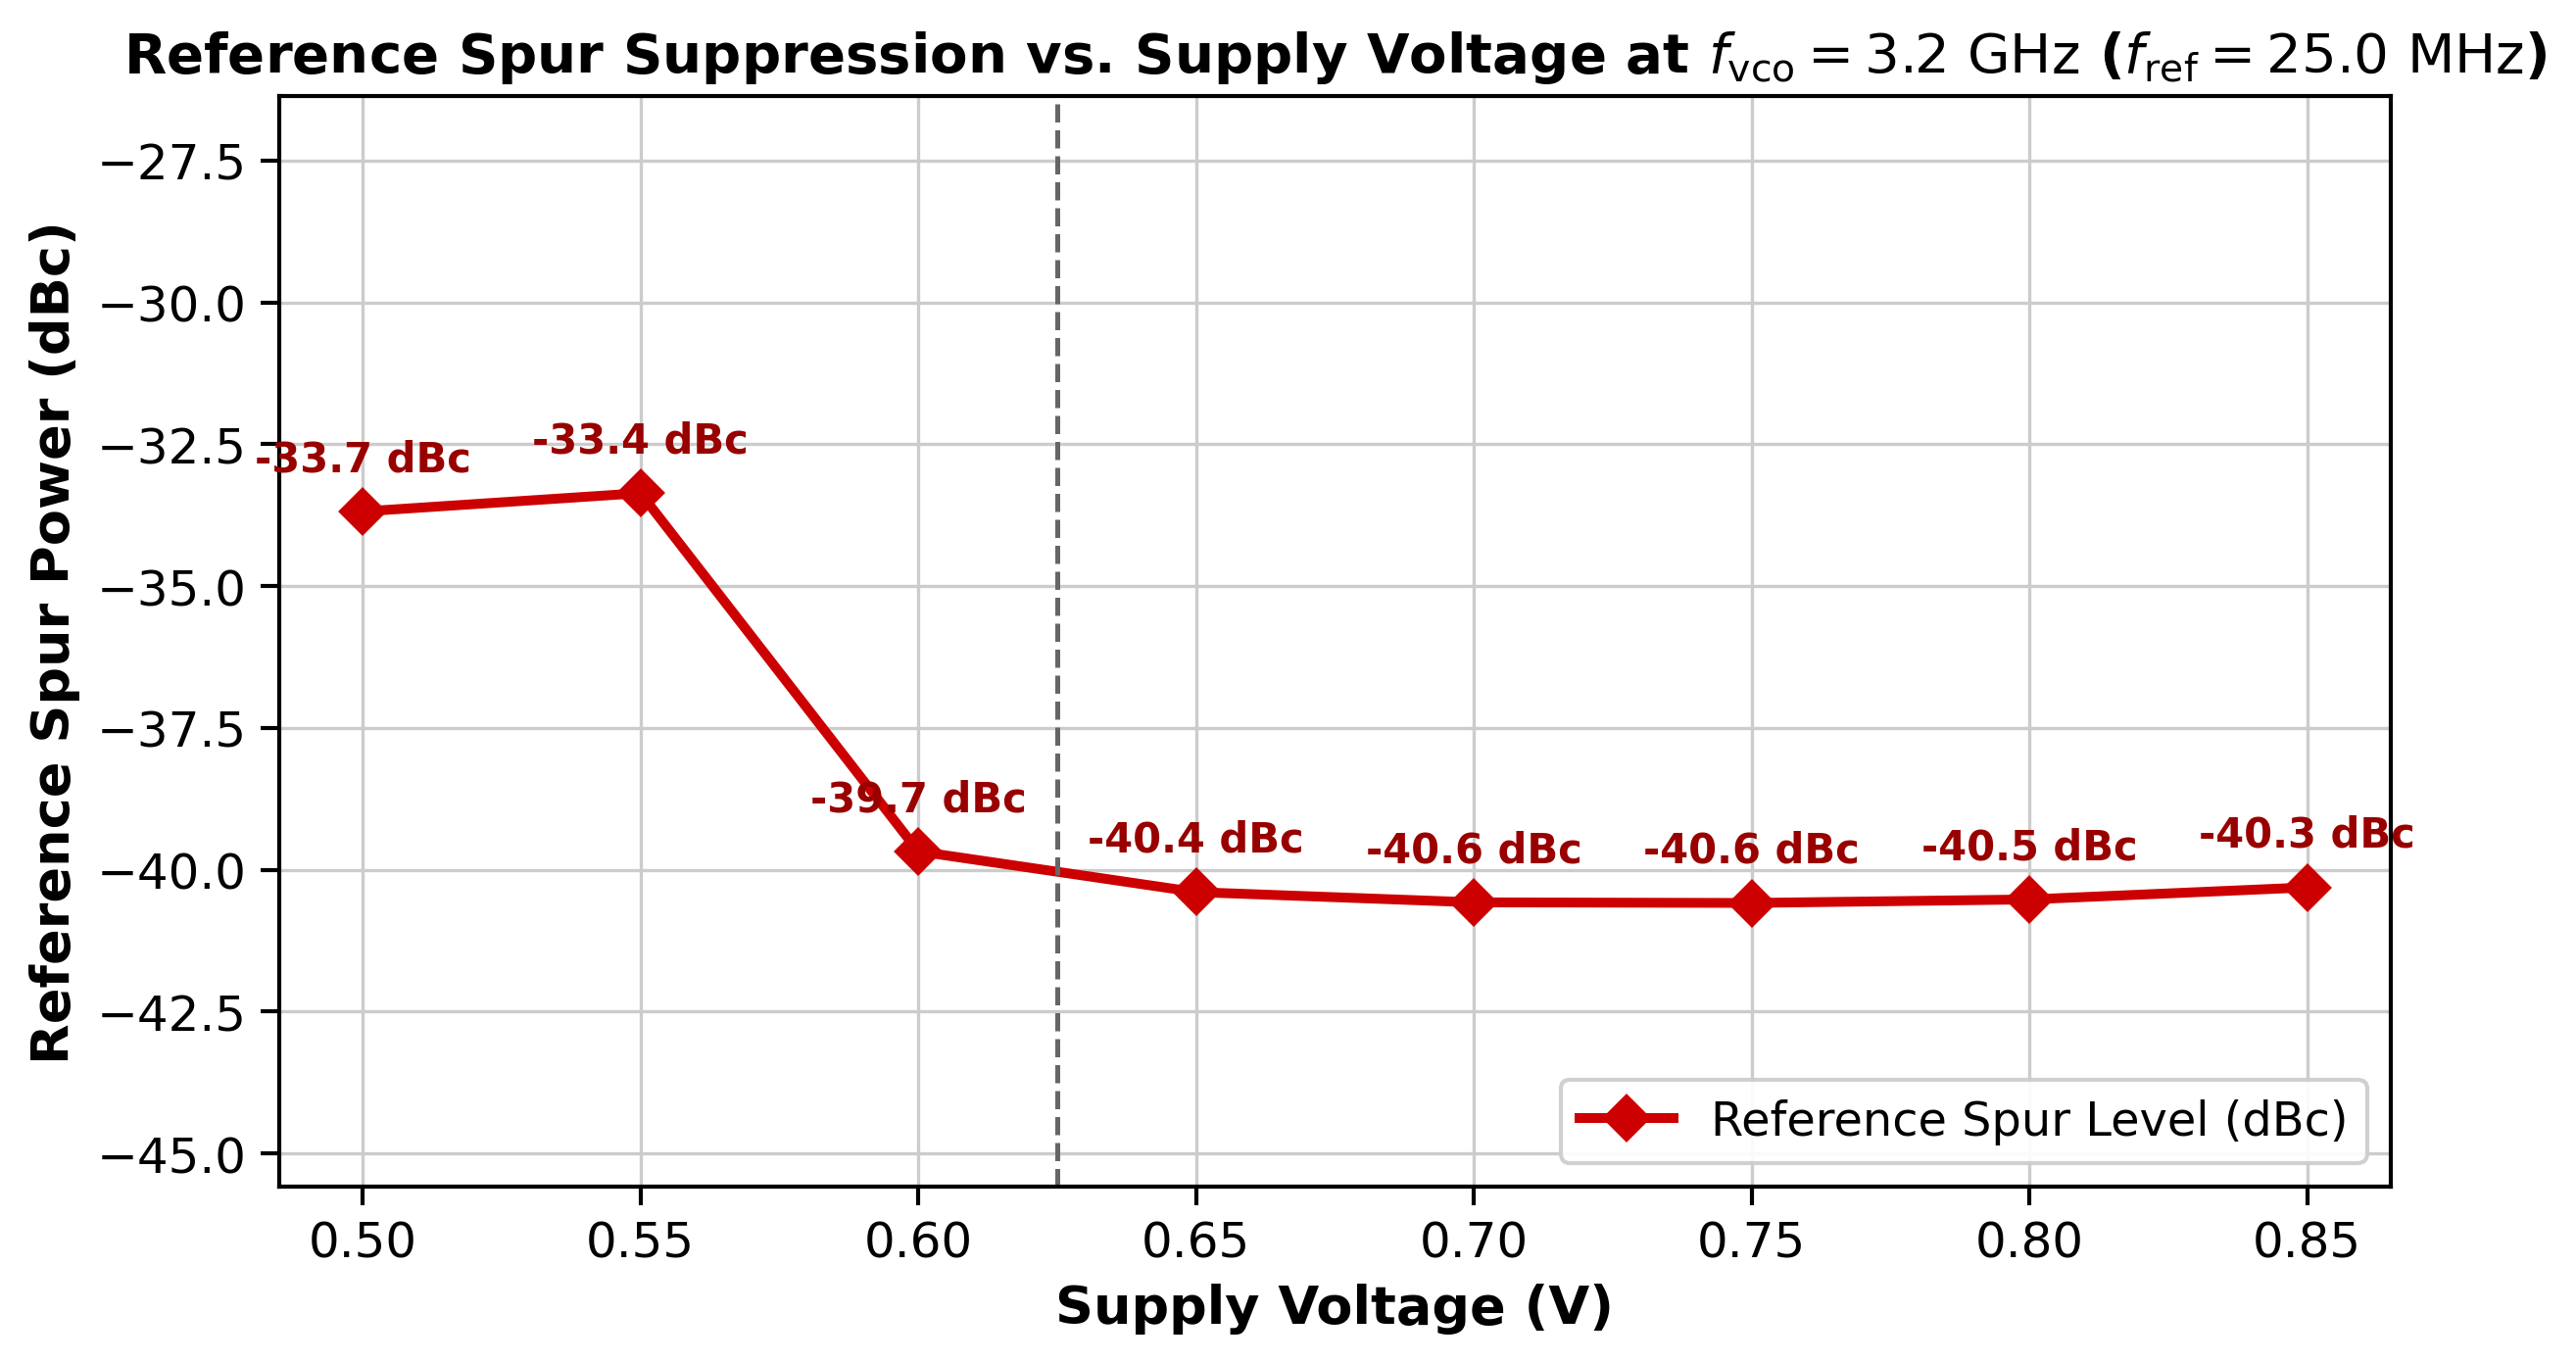

In [37]:
def plot_reference_spur_vs_vdd(df, save_stem="pll_ref_spur_vs_vdd_3.2GHz_ieee", out_dir=PLL_DIR):
    """Plots Reference Spur suppression (dBc) vs Supply Voltage."""
    if "ref_spur_dbc" not in df.columns or df["ref_spur_dbc"].dropna().empty:
        print("No ref_spur_dbc data available.")
        return

    fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)

    v = df["vdd_set"].to_numpy()
    spur = df["ref_spur_dbc"].to_numpy()
    f_ref_mhz = float(df["f_ref"].iloc[0]) / 1e6 if "f_ref" in df.columns and pd.notna(df["f_ref"].iloc[0]) else 25.0

    ax.plot(v, spur, marker="D", color="#cc0000", linewidth=2.4, markersize=7.5, label="Reference Spur Level (dBc)")

    # Transition boundary
    ax.axvline(x=0.625, color="#666666", linestyle="--", linewidth=1.2)

    for vi, si in zip(v, spur):
        if not np.isnan(si):
            ax.annotate(f"{si:.1f} dBc", xy=(vi, si), xytext=(0, 10), textcoords="offset points",
                        ha="center", fontsize=10.0, fontweight="bold", color="#990000")

    ax.set_xlabel("Supply Voltage (V)", fontsize=13.0, fontweight="bold")
    ax.set_ylabel("Reference Spur Power (dBc)", fontsize=13.0, fontweight="bold")
    ax.set_title(rf"Reference Spur Suppression vs. Supply Voltage at $f_{{\mathrm{{vco}}}} = 3.2\ \mathrm{{GHz}}$ ($f_{{\mathrm{{ref}}}} = {f_ref_mhz:.1f}\ \mathrm{{MHz}}$)",
                 fontsize=13.5, fontweight="bold")
    ax.set_xlim(0.485, 0.865)
    ax.set_xticks(np.arange(0.50, 0.86, 0.05))
    ax.set_ylim(bottom=min(spur) - 5, top=max(spur) + 7)
    ax.grid(True, which="major", color="#cccccc", linestyle="-", linewidth=0.8)

    ax.legend(loc="lower right", frameon=True, framealpha=0.92)
    plt.tight_layout()

    if out_dir is not None:
        out_path = Path(out_dir)
        fig.savefig(out_path / f"{save_stem}.pdf", bbox_inches="tight")
        fig.savefig(out_path / f"{save_stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_reference_spur_vs_vdd(df_runs)


### 6. Combined Performance Summary Table

Tabular presentation of all supply operating points, configurations, currents, power, and jitter components across the full $0.50\,\text{V} - 0.85\,\text{V}$ sweep.


In [38]:
summary_cols = [
    "vdd_set", "config_segment", "vco_current_min", "vco_current_max",
    "pll_i_ma", "pll_p_mw", "p_eff_mw_per_ghz", "jitter_ps",
    "time_jitter_noise_ps", "time_jitter_spur_ps", "ref_spur_dbc"
]
avail_cols = [c for c in summary_cols if c in df_runs.columns]
df_table = df_runs[avail_cols].copy()

rename_map = {
    "vdd_set": "VDD Target (V)",
    "config_segment": "Operating Segment",
    "vco_current_min": "I_min",
    "vco_current_max": "I_max",
    "pll_i_ma": "I_core (mA)",
    "pll_p_mw": "P_core (mW)",
    "p_eff_mw_per_ghz": "Power Eff. (mW/GHz)",
    "jitter_ps": "RMS Jitter (ps)",
    "time_jitter_noise_ps": "PNM Noise (ps)",
    "time_jitter_spur_ps": "PNM Spurs (ps)",
    "ref_spur_dbc": "Ref Spur (dBc)",
}
df_table = df_table.rename(columns=rename_map)

pd.set_option("display.precision", 2)
print("=" * 95)
print("  MEASURED PLL PERFORMANCE ACROSS SUPPLY VOLTAGE (3.2 GHz COMBINED, PNM JITTER)")
print("=" * 95)
try:
    from IPython.display import display
    display(df_table)
except ImportError:
    print(df_table.to_string())


  MEASURED PLL PERFORMANCE ACROSS SUPPLY VOLTAGE (3.2 GHz COMBINED, PNM JITTER)


,VDD Target (V),Operating Segment,I_min,I_max,I_core (mA),P_core (mW),Power Eff. (mW/GHz),RMS Jitter (ps),PNM Noise (ps),PNM Spurs (ps),Ref Spur (dBc)
0,0.50,"Low-VDD Config (c=0, min=11, max=2)",11,2,0.78,0.39,0.12,39.39,39.42,0.89,-33.69
1,0.55,"Low-VDD Config (c=0, min=11, max=2)",11,2,0.82,0.45,0.14,27.43,27.41,1.20,-33.36
2,0.60,"Low-VDD Config (c=1, min=8, max=8)",8,8,1.01,0.61,0.19,19.77,19.75,0.86,-39.68
3,0.65,"High-VDD Config (c=1, min=8, max=8)",8,8,1.04,0.68,0.21,17.07,17.05,0.71,-40.39
4,0.70,"High-VDD Config (c=1, min=8, max=8)",8,8,1.07,0.75,0.23,15.47,15.46,0.65,-40.58
5,0.75,"High-VDD Config (c=1, min=8, max=8)",8,8,1.10,0.82,0.26,15.12,15.13,0.68,-40.59
6,0.80,"High-VDD Config (c=1, min=8, max=8)",8,8,1.13,0.91,0.28,13.69,13.65,0.67,-40.52
7,0.85,"High-VDD Config (c=1, min=8, max=8)",8,8,1.17,0.99,0.31,13.34,13.33,0.68,-40.31
